In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron #used for simple linear classification tasks.
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential #Sequential lets you build a neural network
from tensorflow.keras.layers import Dense #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D #Conv2D extracts features
from tensorflow.keras.layers import Flatten # Flatten reshapes them
from tensorflow.keras.layers import MaxPooling2D #MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout #Dropout prevents overfitting
from tensorflow.keras.utils import to_categorical #converts numeric class labels into one-hot encoded format for training classification models

In [2]:

from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()


In [3]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [4]:
X_train

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [5]:
y_train


array([9, 0, 0, ..., 3, 0, 5], shape=(60000,), dtype=uint8)

In [6]:
X_test

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [7]:
y_test

array([9, 2, 1, ..., 8, 1, 5], shape=(10000,), dtype=uint8)

In [8]:
X_train[:5]

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
   

In [9]:
# Preprocessing
#Normalize pixels
X_train = X_train.astype("float32")/ 255.0
X_test = X_test.astype("float32")/ 255.0

#create validation data
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size = 0.2, random_state = 42, stratify = y_train)

#Flatten images for perceptron
X_train_per = X_train.reshape(-1, 784)
X_val_per = X_val.reshape(-1, 784)
X_test_per = X_test.reshape(-1, 784)

#One hot encode labels
y_train_cat = to_categorical(y_train, 10)
y_val_cat = to_categorical(y_val, 10)
y_test_cat  = to_categorical(y_test, 10)


In [10]:
print(X_train.shape)
print(y_train_cat.shape)

(48000, 28, 28)
(48000, 10)


# Perceptron

In [11]:
perceptron = Sequential([
    Dense(10, activation = "softmax", input_shape = (784, ))
])

In [12]:
perceptron.compile(
    optimizer = 'sgd',
    loss = 'categorical_crossentropy',
    metrics = ['accuracy']
)

In [13]:
history_perceptron = perceptron.fit(
    X_train_per,
    y_train_cat,
    epochs = 10,
    batch_size = 32,
    validation_data = (X_val_per, y_val_cat),
    verbose = 1
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7263 - loss: 0.8762 - val_accuracy: 0.7947 - val_loss: 0.6538
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8004 - loss: 0.6173 - val_accuracy: 0.8137 - val_loss: 0.5726
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8166 - loss: 0.5639 - val_accuracy: 0.8257 - val_loss: 0.5351
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8231 - loss: 0.5350 - val_accuracy: 0.8292 - val_loss: 0.5164
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8284 - loss: 0.5159 - val_accuracy: 0.8355 - val_loss: 0.4976
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8327 - loss: 0.5021 - val_accuracy: 0.8393 - val_loss: 0.4838
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8356 - loss: 0.4910 - val_accuracy: 0.8388 - val_loss: 0.4769
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8391 - loss: 0.4828 - 

In [14]:
test_loss, test_accuracy = perceptron.evaluate(
    X_test_per,
    y_test_cat,
    verbose = 1
)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8298 - loss: 0.4961
Test Accuracy: 0.829800009727478


In [15]:
print("Training Accuracy:")
print(history_perceptron.history["accuracy"])

print("\nTraining Loss:")
print(history_perceptron.history["loss"])

print("\nValidation Accuracy:")
print(history_perceptron.history["val_accuracy"])

print("\nValidation Loss:")
print(history_perceptron.history["val_loss"])

Training Accuracy:
[0.726312518119812, 0.8004166483879089, 0.8165624737739563, 0.8230624794960022, 0.828416645526886, 0.832687497138977, 0.835604190826416, 0.839104175567627, 0.8413125276565552, 0.8420624732971191]

Training Loss:
[0.876207172870636, 0.6172542572021484, 0.5638761520385742, 0.5350237488746643, 0.5159221887588501, 0.5021498203277588, 0.4910261631011963, 0.4827747046947479, 0.4756987392902374, 0.4693154990673065]

Validation Accuracy:
[0.7946666479110718, 0.8136666417121887, 0.8256666660308838, 0.8291666507720947, 0.8355000019073486, 0.8393333554267883, 0.8387500047683716, 0.8415833115577698, 0.8453333377838135, 0.8445833325386047]

Validation Loss:
[0.6538293361663818, 0.5725680589675903, 0.5350724458694458, 0.5164390802383423, 0.4976046085357666, 0.48376917839050293, 0.47692859172821045, 0.4683862328529358, 0.4621666669845581, 0.45734524726867676]


In [16]:
for epoch in range(10):
    print(f"Epoch {epoch + 1}")
    print("Training Accuracy:", history_perceptron.history["accuracy"][epoch])
    print("Training Loss:", history_perceptron.history["loss"][epoch])
    print("Validation Accuracy:", history_perceptron.history["val_accuracy"][epoch])
    print("Validation Loss:", history_perceptron.history["val_loss"][epoch])
    print()

Epoch 1
Training Accuracy: 0.726312518119812
Training Loss: 0.876207172870636
Validation Accuracy: 0.7946666479110718
Validation Loss: 0.6538293361663818

Epoch 2
Training Accuracy: 0.8004166483879089
Training Loss: 0.6172542572021484
Validation Accuracy: 0.8136666417121887
Validation Loss: 0.5725680589675903

Epoch 3
Training Accuracy: 0.8165624737739563
Training Loss: 0.5638761520385742
Validation Accuracy: 0.8256666660308838
Validation Loss: 0.5350724458694458

Epoch 4
Training Accuracy: 0.8230624794960022
Training Loss: 0.5350237488746643
Validation Accuracy: 0.8291666507720947
Validation Loss: 0.5164390802383423

Epoch 5
Training Accuracy: 0.828416645526886
Training Loss: 0.5159221887588501
Validation Accuracy: 0.8355000019073486
Validation Loss: 0.4976046085357666

Epoch 6
Training Accuracy: 0.832687497138977
Training Loss: 0.5021498203277588
Validation Accuracy: 0.8393333554267883
Validation Loss: 0.48376917839050293

Epoch 7
Training Accuracy: 0.835604190826416
Training Loss: 0

# ANN(Artificial Neural Network)

In [17]:
# Step1: Create ANN model
ann = Sequential([
    Dense(128, activation = 'relu', input_shape=(784,)),
    Dense(64, activation = 'relu'),
    Dense(10, activation = 'softmax')
])

In [18]:
#step2: Compile ANN
ann.compile(
    optimizer = 'adam',
    loss = 'categorical_crossentropy',
    metrics = ['accuracy']
)

In [19]:
#Step3: Train ANN
history_ann = ann.fit(
    X_train_per,
    y_train_cat,
    epochs = 10,
    batch_size = 32,
    validation_data = (X_val_per, y_val_cat),
    verbose = 1
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8169 - loss: 0.5140 - val_accuracy: 0.8372 - val_loss: 0.4393
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8597 - loss: 0.3820 - val_accuracy: 0.8663 - val_loss: 0.3766
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8737 - loss: 0.3413 - val_accuracy: 0.8752 - val_loss: 0.3447
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8820 - loss: 0.3190 - val_accuracy: 0.8754 - val_loss: 0.3373
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8885 - loss: 0.3000 - val_accuracy: 0.8813 - val_loss: 0.3337
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8935 - loss: 0.2854 - val_accuracy: 0.8861 - val_loss: 0.3171
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8979 - loss: 0.2723 - val_accuracy: 0.8883 - val_loss: 0.3083
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9028 - loss: 0.2610 - 

In [20]:
#step4: Test ANN
test_loss_ann, test_accuracy_ann = ann.evaluate(
    X_test_per,
    y_test_cat,
    verbose = 1
)
print("ANN Test Accuracy:", test_accuracy_ann)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8792 - loss: 0.3522
ANN Test Accuracy: 0.8791999816894531


In [21]:
print("Training Accuracy:",
      history_ann.history["accuracy"][-1])

print("Training Loss:",
      history_ann.history["loss"][-1])

print("Validation Accuracy:",
      history_ann.history["val_accuracy"][-1])

print("Validation Loss:",
      history_ann.history["val_loss"][-1])


Training Accuracy: 0.909250020980835
Training Loss: 0.2417711764574051
Validation Accuracy: 0.890333354473114
Validation Loss: 0.32286134362220764


# CNN (Convolutional Neural Network)

In [22]:
#step1: Prepare data for CNN
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_val_cnn = X_val.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

In [24]:
#Step2: Create CNN model
cnn = Sequential([
    Conv2D(
        filters = 32,
        kernel_size = (3,3),
        activation = 'relu',
        input_shape = (28, 28, 1)
    ),
    MaxPooling2D(pool_size = (2,2)),
    Dropout(0.25),

    Conv2D(
        filters = 64,
        kernel_size = (3,3),
        activation = 'relu'
    ),
    MaxPooling2D(pool_size = (2, 2)),

    Dropout(0.25),

    Flatten(),
    Dense(128, activation = 'relu'),

    Dropout(0.5),
     Dense(10, activation ="softmax")
])


In [28]:
#Step3: Compile
cnn.compile(
    optimizer = 'adam',
    loss = 'categorical_crossentropy',
    metrics = ['accuracy']
)

In [29]:
#step4: Model Summary
cnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
#step5: Train
history_cnn = cnn.fit(
    X_train_cnn,
    y_train_cat,
    epochs = 10,
    batch_size = 32,
    validation_data = (X_val_cnn, y_val_cat),
    verbose = 1)
    

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.7986 - loss: 0.5421 - val_accuracy: 0.8603 - val_loss: 0.3851
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.8454 - loss: 0.4250 - val_accuracy: 0.8833 - val_loss: 0.3306
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.8642 - loss: 0.3719 - val_accuracy: 0.8932 - val_loss: 0.2913
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.8722 - loss: 0.3490 - val_accuracy: 0.8971 - val_loss: 0.2726
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.8805 - loss: 0.3245 - val_accuracy: 0.9026 - val_loss: 0.2641
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.8864 - loss: 0.3113 - val_accuracy: 0.9032 - val_loss: 0.2570
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.8873 - loss: 0.3027 - val_accuracy: 0.9049 - val_loss: 0.2512
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.8909 - 

In [31]:
#Step6: Final test evaluation
test_loss_cnn, test_accuracy_cnn = cnn.evaluate(
    X_test_cnn,
    y_test_cat,
    verbose = 1
)
print("CNN Test Accuracy: ", test_accuracy_cnn)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9019 - loss: 0.2659
CNN Test Accuracy:  0.9018999934196472


In [33]:

print("Training Accuracy:",
      history_cnn.history["accuracy"][-1])

print("Training Loss:",
      history_cnn.history["loss"][-1])

print("Validation Accuracy:",
      history_cnn.history["val_accuracy"][-1])

print("Validation Loss:",
      history_cnn.history["val_loss"][-1])

print("Test Accuracy:",
      test_accuracy_cnn)

print("Test Loss:",
      test_loss_cnn)

Training Accuracy: 0.8962708115577698
Training Loss: 0.2823488414287567
Validation Accuracy: 0.9086666703224182
Validation Loss: 0.249872088432312
Test Accuracy: 0.9018999934196472
Test Loss: 0.26593565940856934


In [35]:
import matplotlib.pyplot as plt

def plot_training(history, title):
    plt.figure(figsize=(12, 4))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Train")
    plt.plot(history.history["val_accuracy"], label="Validation")
    plt.title(f"{title} Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Train")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.title(f"{title} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.show()

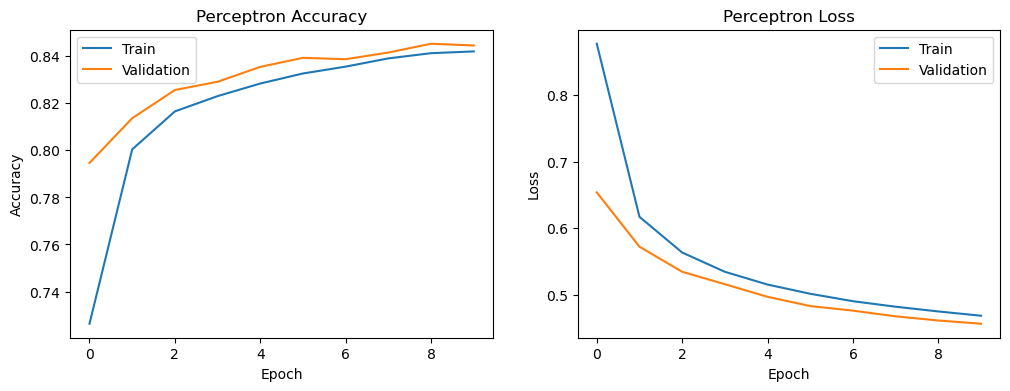

In [36]:
plot_training(history_perceptron, "Perceptron")

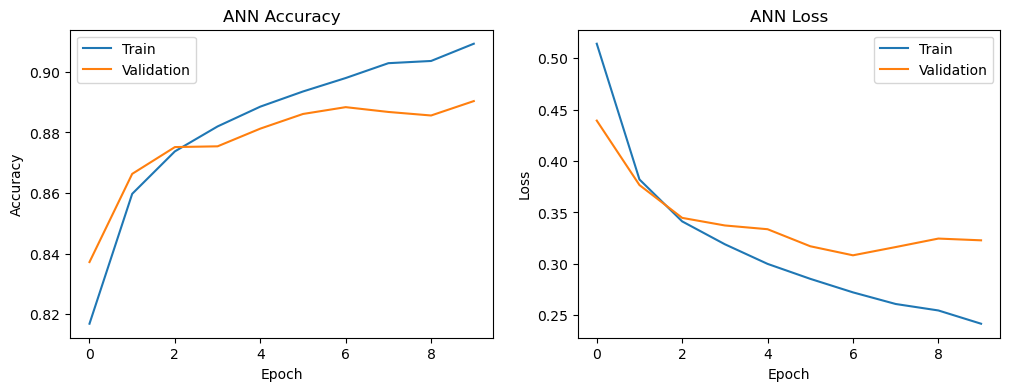

In [37]:
plot_training(history_ann, "ANN")

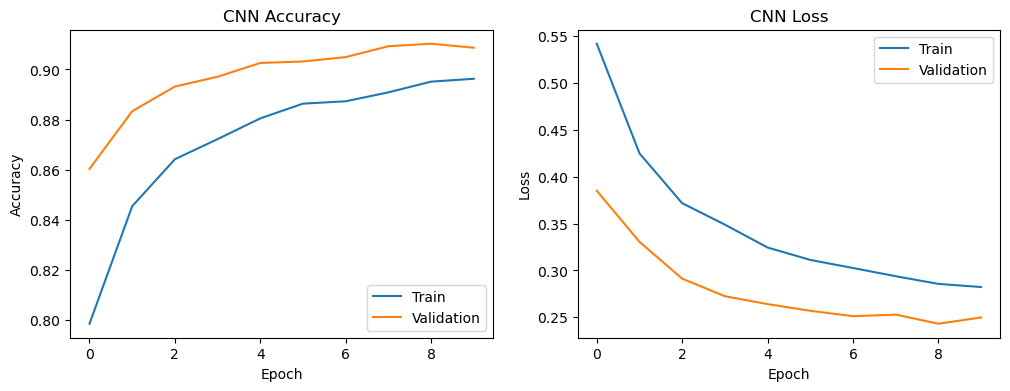

In [38]:
plot_training(history_cnn, "CNN")

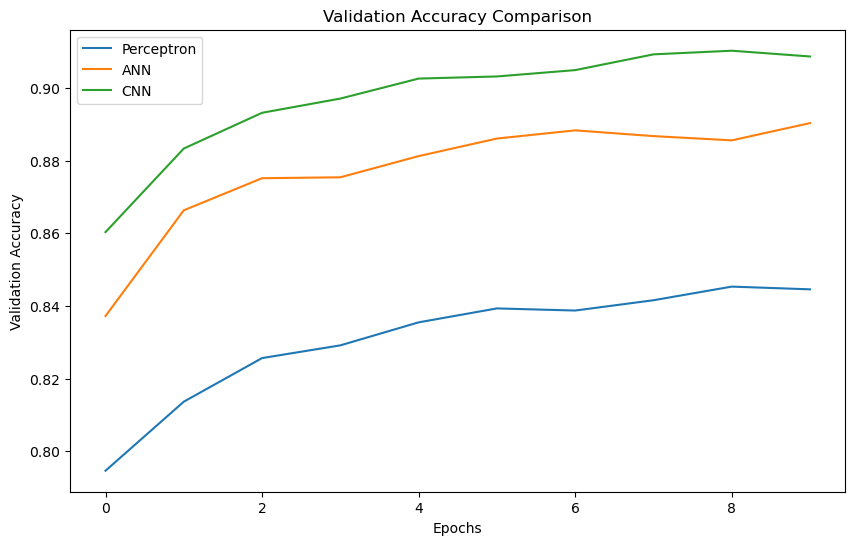

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    history_perceptron.history["val_accuracy"],
    label="Perceptron"
)

plt.plot(
    history_ann.history["val_accuracy"],
    label="ANN"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="CNN"
)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

In [44]:
import numpy as np
import matplotlib.pyplot as plt

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]


def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):

    idxs = np.random.choice(len(X), n, replace=False)

    plt.figure(figsize=(15, 6))

    for i, idx in enumerate(idxs):

        # Original image
        plt.subplot(2, n, i + 1)

        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")

        true_label = class_names[y_true[idx]]
        plt.title(f"True: {true_label}")

        # Predictions
        preds = []

        for model, name in zip(models, model_names):

            if name == "CNN":
                input_data = X_cnn[idx].reshape(1, 28, 28, 1)
            else:
                input_data = X[idx].reshape(1, 784)

            prediction = model.predict(input_data, verbose=0)

            predicted_class = np.argmax(prediction)

            preds.append(class_names[predicted_class])

        # Prediction results
        plt.subplot(2, n, n + i + 1)
        plt.axis("off")

        prediction_text = "\n".join(
            f"{name}: {pred}"
            for name, pred in zip(model_names, preds)
        )

        plt.title(prediction_text)

    plt.tight_layout()
    plt.show()

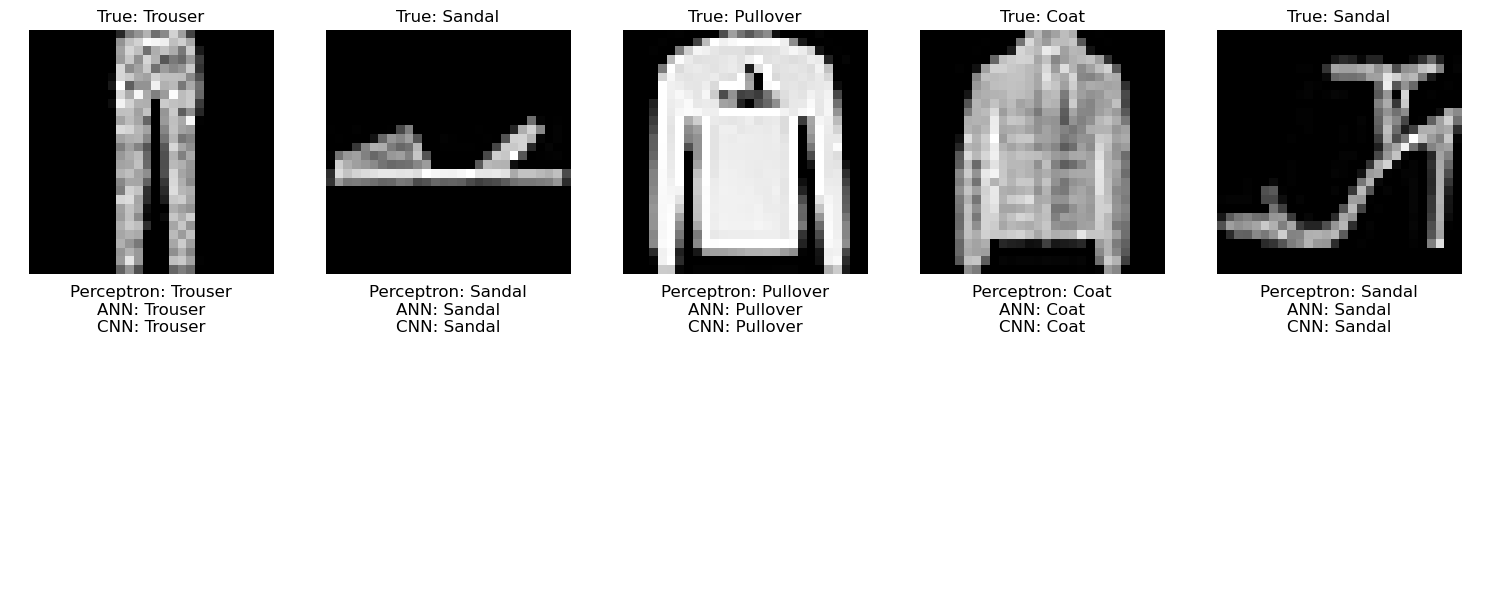

In [48]:
models = [perceptron, ann, cnn]

model_names = ["Perceptron", "ANN", "CNN"]

show_side_by_side(
    models,
    model_names,
    X_test_per,
    X_test_cnn,
    y_test,
    n=5
)

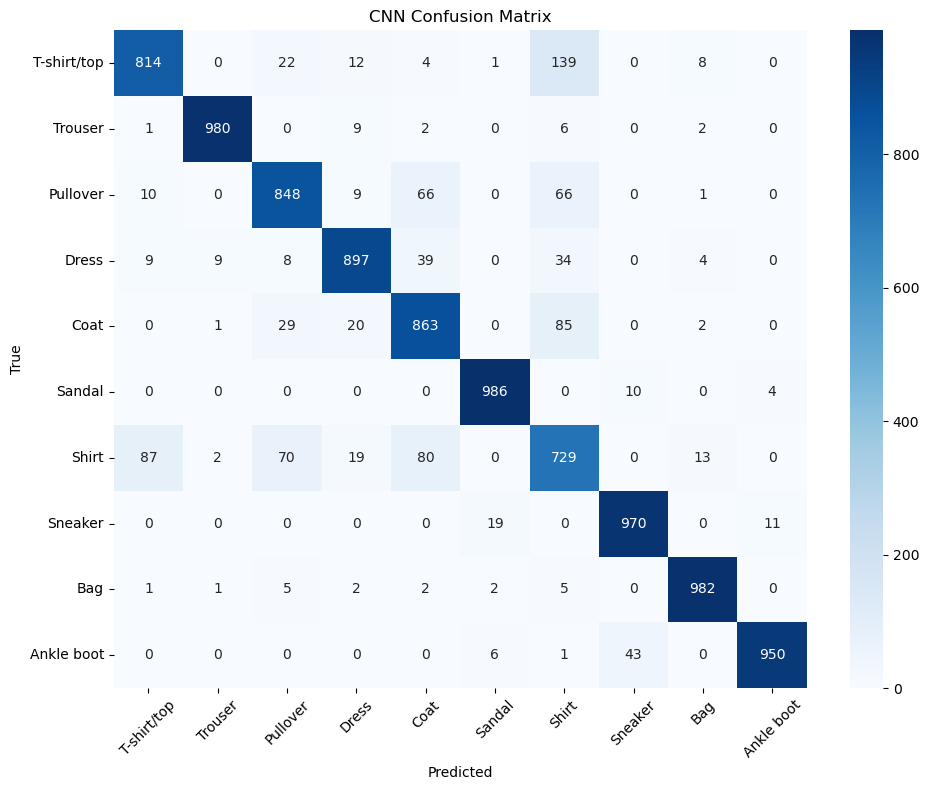

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Predict classes
y_pred_cnn = np.argmax(
    cnn.predict(X_test_cnn, verbose=0),
    axis=1
)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_cnn)

# Plot confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

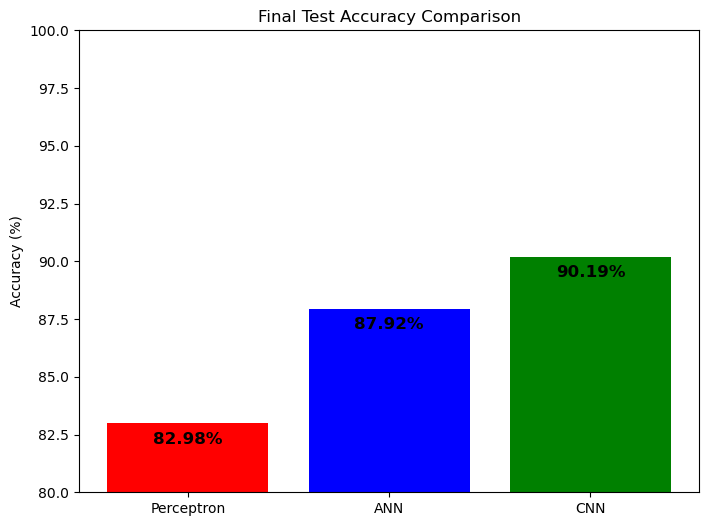

In [51]:
import matplotlib.pyplot as plt

# Get final test accuracy
_, acc_percp = perceptron.evaluate(
    X_test_per,
    y_test_cat,
    verbose=0
)

_, acc_ann = ann.evaluate(
    X_test_per,
    y_test_cat,
    verbose=0
)

_, acc_cnn = cnn.evaluate(
    X_test_cnn,
    y_test_cat,
    verbose=0
)


# Convert accuracy to percentage
final_accs = [
    acc_percp * 100,
    acc_ann * 100,
    acc_cnn * 100
]

models = [
    "Perceptron",
    "ANN",
    "CNN"
]


# Create bar chart

plt.figure(figsize=(8, 6))

bars = plt.bar(models, final_accs,
              color = ['red', 'blue', 'green'])

plt.title("Final Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")


# Display accuracy on each bar
for bar, acc in zip(bars, final_accs):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() - 1,
        f"{acc:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )


plt.ylim(80, 100)
plt.show()